### Import the libraries required for data analysis, visualization, and the ANN model.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report)

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping
print(f"TensorFlow version: {tf.__version__}")

TensorFlow version: 2.22.0-rc0


### Load the Seeds dataset from the project CSV file.

In [2]:
df = pd.read_csv("seeds_new (1).csv")
print(f"Dataset loaded: {df.shape[0]} rows and {df.shape[1]} columns.")

Dataset loaded: 210 rows and 10 columns.


### Normalize whitespace-only fields and remove columns that contain no data.

In [3]:
columns_before = df.shape[1]
df = df.replace(r"^\s*$", np.nan, regex=True)
df = df.dropna(axis=1, how="all")
print(f"Removed {columns_before - df.shape[1]} empty columns; {df.shape[1]} columns remain.")

Removed 2 empty columns; 8 columns remain.


### Separate input features from the target class and display dataset dimensions.

In [4]:
X = df.drop("Class (1, 2, 3)", axis=1)
y_original = df["Class (1, 2, 3)"]

print(f"Input features: {X.shape[1]} columns across {X.shape[0]} samples.")
print(f"Target labels: {y_original.shape[0]} samples.")

Input features: 7 columns across 210 samples.
Target labels: 210 samples.


### Encode the three target classes as zero-based labels for model training.

In [5]:
y = y_original - 1
print(f"Original seed classes: {sorted(y_original.unique())}")
print(f"Encoded labels for ANN training: {sorted(y.unique())}")

Original seed classes: [np.int64(1), np.int64(2), np.int64(3)]
Encoded labels for ANN training: [np.int64(0), np.int64(1), np.int64(2)]


### Plot histograms to inspect distributions of the numeric input features.

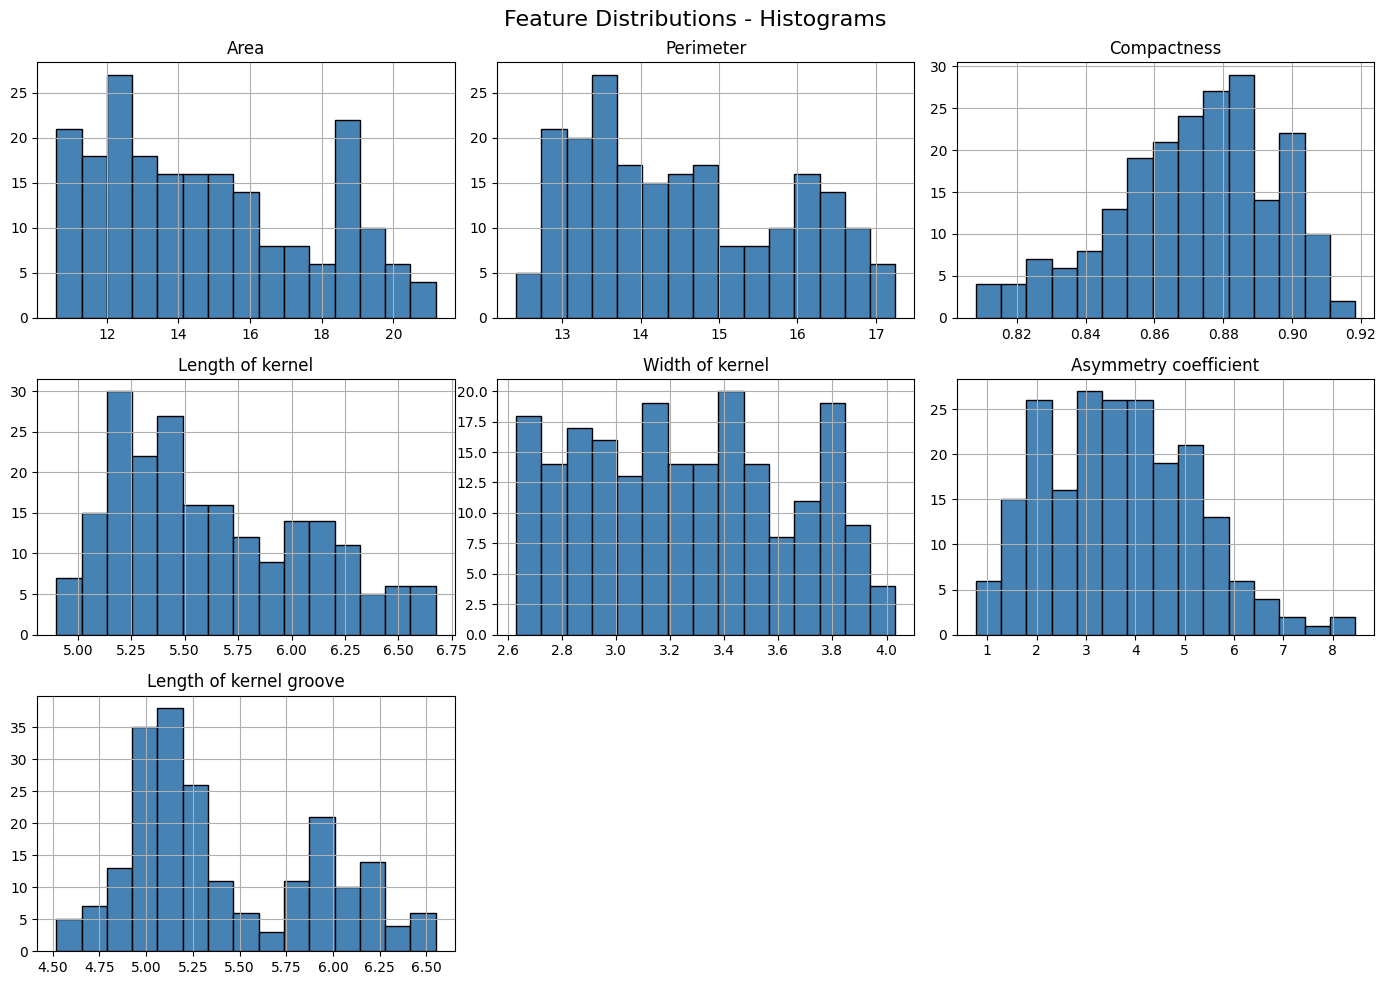

In [6]:
X.hist(figsize=(14, 10), bins=15, color="steelblue", edgecolor="black")
plt.suptitle("Feature Distributions - Histograms", fontsize=16)
plt.tight_layout()
plt.show()

### Plot kernel length against kernel width, colored by seed class.

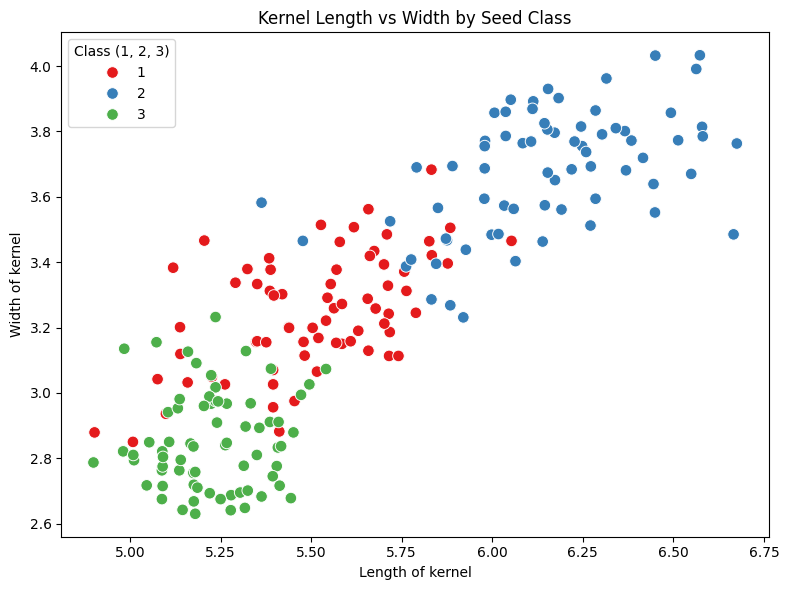

In [7]:
plt.figure(figsize=(8, 6))
sns.scatterplot(data=df, x="Length of kernel", y="Width of kernel", hue="Class (1, 2, 3)", palette="Set1", s=70)
plt.title("Kernel Length vs Width by Seed Class")
plt.xlabel("Length of kernel")
plt.ylabel("Width of kernel")
plt.tight_layout()
plt.show()

### Compare kernel area measurements across seed classes with a box plot.

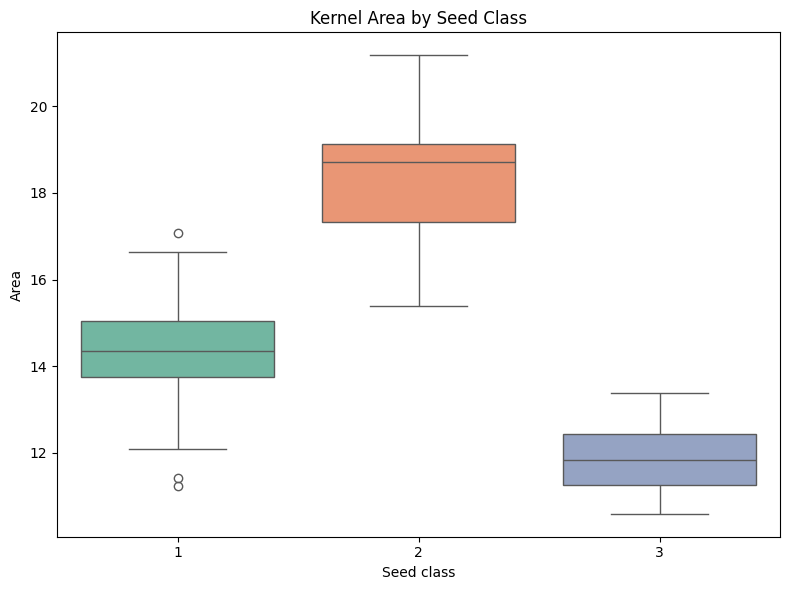

In [8]:
plt.figure(figsize=(8, 6))
sns.boxplot(data=df, x="Class (1, 2, 3)", y="Area", hue="Class (1, 2, 3)", palette="Set2", legend=False)
plt.title("Kernel Area by Seed Class")
plt.xlabel("Seed class")
plt.ylabel("Area")
plt.tight_layout()
plt.show()

### Display feature-to-feature correlations in a heatmap.

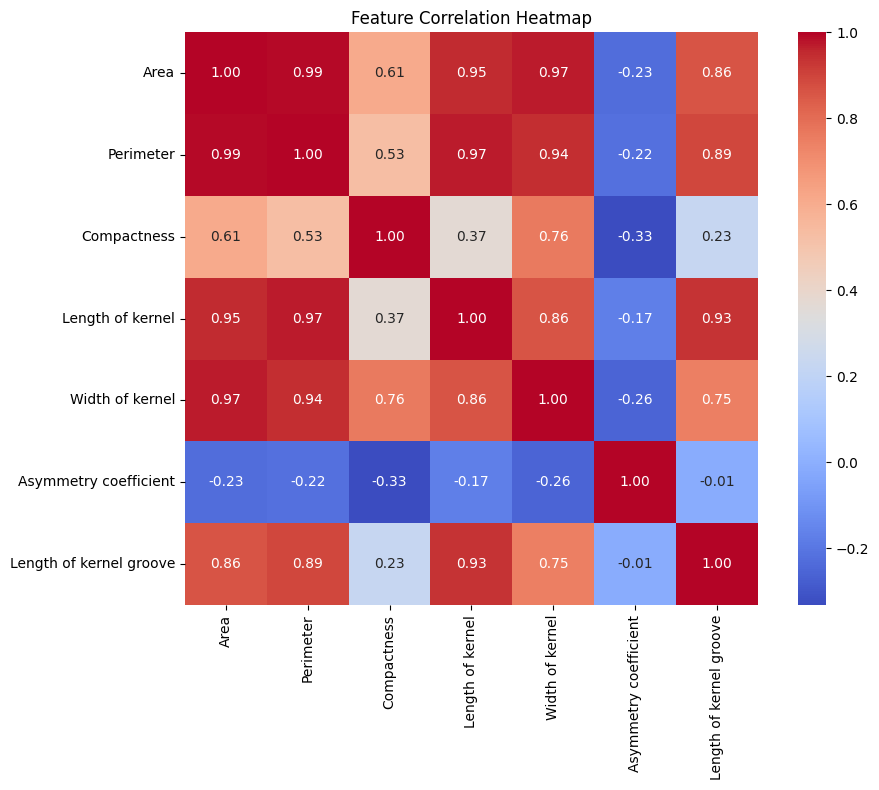

In [9]:
plt.figure(figsize=(10, 8))
sns.heatmap(X.corr(), annot=True, cmap="coolwarm", fmt=".2f", square=True)
plt.title("Feature Correlation Heatmap")
plt.tight_layout()
plt.show()

### Show the number of seed samples in each class with a bar plot.

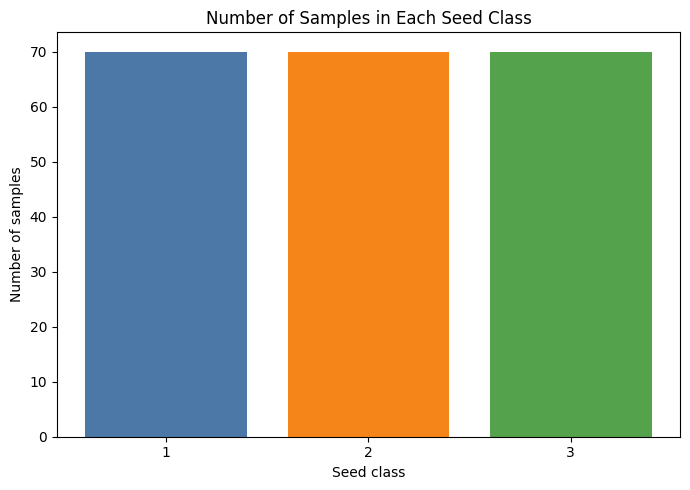

Samples per class:
Class (1, 2, 3)
1    70
2    70
3    70


In [10]:
class_counts = y_original.value_counts().sort_index()
plt.figure(figsize=(7, 5))
plt.bar(class_counts.index.astype(str), class_counts.values, color=["#4C78A8", "#F58518", "#54A24B"])
plt.title("Number of Samples in Each Seed Class")
plt.xlabel("Seed class")
plt.ylabel("Number of samples")
plt.xticks(class_counts.index.astype(str))
plt.tight_layout()
plt.show()
print("Samples per class:")
print(class_counts.to_string())

### Create stratified training and testing splits and report their sizes.

In [11]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)

print(f"Training set: {X_train.shape[0]} samples.")
print(f"Testing set: {X_test.shape[0]} samples.")

Training set: 168 samples.
Testing set: 42 samples.


### Standardize input features using the training split and transform the test split.

In [12]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
print(f"Standardized {X_train_scaled.shape[1]} features for training and testing.")

Standardized 7 features for training and testing.


### Build a neural network with an output unit for each seed class.

In [13]:
model = Sequential([
    Input(shape=(X_train_scaled.shape[1],)),
    Dense(16, activation="relu"),
    Dense(8, activation="relu"),
    Dense(3, activation="softmax")
])
print("ANN architecture:")
model.summary()

ANN architecture:


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 3)              │            27 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 291 (1.14 KB)

 Trainable params: 291 (1.14 KB)

 Non-trainable params: 0 (0.00 B)

### Compile the ANN with the optimizer, classification loss, and accuracy metric.

In [14]:
model.compile(optimizer=Adam(learning_rate=0.001), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
print("ANN compiled with Adam, sparse categorical cross-entropy, and accuracy.")

ANN compiled with Adam, sparse categorical cross-entropy, and accuracy.


### Configure early stopping to retain the best validation-loss model weights.

In [15]:
early_stop = EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True)
print("Early stopping enabled: monitor=val_loss, patience=10, restore_best_weights=True.")

Early stopping enabled: monitor=val_loss, patience=10, restore_best_weights=True.


### Train the ANN and record training and validation metrics.

In [16]:
history = model.fit(
    X_train_scaled,
    y_train,
    epochs=100,
    batch_size=32,
    validation_split=0.20,
    callbacks=[early_stop],
    verbose=1
)
print(f"Training completed after {len(history.history['loss'])} epochs.")

Epoch 1/100



1/5 ━━━━━━━━━━━━━━━━━━━━ 1s 321ms/step - accuracy: 0.2188 - loss: 1.1342


5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step - accuracy: 0.2910 - loss: 1.1157 


5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 81ms/step - accuracy: 0.2910 - loss: 1.1157 - val_accuracy: 0.2647 - val_loss: 1.0993


Epoch 2/100


...


5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.9403 - loss: 0.1042 - val_accuracy: 0.9706 - val_loss: 0.1334


Epoch 100/100



1/5 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.9375 - loss: 0.1098


5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.9403 - loss: 0.1028 - val_accuracy: 0.9706 - val_loss: 0.1316


Training completed after 100 epochs.


### Plot training and validation accuracy over the training epochs.

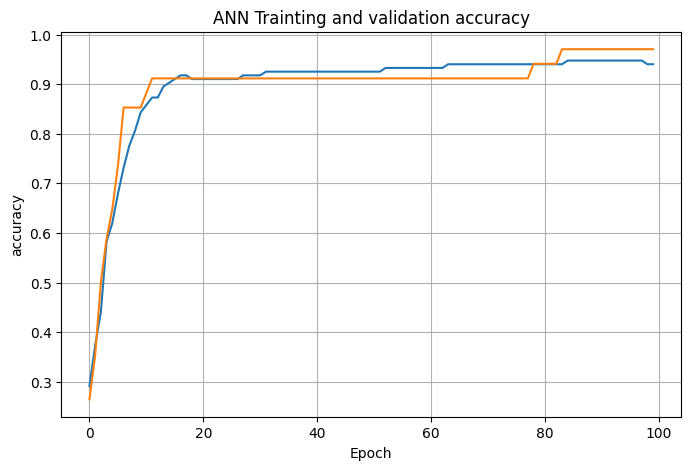

In [17]:
plt.figure(figsize=(8, 5))
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.title("ANN Trainting and validation accuracy")
plt.xlabel("Epoch")
plt.ylabel("accuracy")
plt.grid(True)
plt.show()

### Evaluate the trained ANN on the held-out test split.

In [18]:
test_loss, test_accuracy = model.evaluate(X_test_scaled, y_test, verbose=0)
print(f"Test-set loss: {test_loss:.4f}")
print(f"Test-set accuracy: {test_accuracy:.2%}")

Test-set loss: 0.3075
Test-set accuracy: 88.10%


### Predict class probabilities for the held-out samples.

In [19]:
y_prob = model.predict(X_test_scaled, verbose=0)
print("Predicted class probabilities for the first five test samples:")
print(np.round(y_prob[:5], 3))

Predicted class probabilities for the first five test samples:
[[0.978 0.006 0.016]
 [0.059 0.018 0.923]
 [0.272 0.651 0.077]
 [0.004 0.003 0.993]
 [0.001 0.999 0.   ]]


### Convert predicted class probabilities into encoded class labels.

In [20]:
y_pred = np.argmax(y_prob, axis=1)
print("Predicted encoded class labels (first 10 test samples):")
print(y_pred[:10])

Predicted encoded class labels (first 10 test samples):
[0 2 1 2 1 2 1 1 1 1]


### Convert predicted and actual labels back to the original class numbers.

In [21]:
y_pred_original = y_pred + 1
y_test_original = y_test + 1
print("Predicted original class labels (first 10 test samples):")
print(y_pred_original[:10])

Predicted original class labels (first 10 test samples):
[1 3 2 3 2 3 2 2 2 2]


### Compare actual and predicted classes for the test samples.

In [22]:
comparison = pd.DataFrame({"Actual Class": y_test_original.values, "Predicted Class": y_pred_original})
print("Actual and predicted classes for the first five test samples:")
comparison.head(5)

Actual and predicted classes for the first five test samples:


,Actual Class,Predicted Class
0,1,1
1,3,3
2,2,2
3,3,3
4,2,2


### Calculate overall test accuracy.

In [23]:
accuracy = accuracy_score(y_test_original, y_pred_original)
print(f"Test accuracy: {accuracy:.2%}")

Test accuracy: 88.10%


### Calculate weighted test precision.

In [24]:
precision = precision_score(y_test_original, y_pred_original, average="weighted")
print(f"Weighted test precision: {precision:.2%}")

Weighted test precision: 89.95%


### Calculate weighted test recall.

In [25]:
recall = recall_score(y_test_original, y_pred_original, average="weighted")
print(f"Weighted test recall: {recall:.2%}")

Weighted test recall: 88.10%


### Calculate weighted test F1 score.

In [26]:
f1 = f1_score(y_test_original, y_pred_original, average="weighted")
print(f"Weighted test F1 score: {f1:.2%}")

Weighted test F1 score: 87.31%


### Summarize the evaluation metrics in a table.

In [27]:
metrics = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1 score"],
    "Score": [accuracy, precision, recall, f1]
})
metrics

,Metric,Score
0,Accuracy,0.880952
1,Precision,0.899510
2,Recall,0.880952
3,F1 score,0.873056


### Print a detailed precision, recall, and F1 classification report.

In [28]:
print("Classification report for the held-out test samples:")
print(classification_report(y_test_original, y_pred_original, zero_division=0))

Classification report for the held-out test samples:
              precision    recall  f1-score   support

           1       1.00      0.64      0.78        14
           2       0.82      1.00      0.90        14
           3       0.88      1.00      0.93        14

    accuracy                           0.88        42
   macro avg       0.90      0.88      0.87        42
weighted avg       0.90      0.88      0.87        42



### Calculate and display the confusion-matrix counts.

In [29]:
cm = confusion_matrix(y_test_original, y_pred_original)
print("Confusion matrix (rows = actual classes, columns = predicted classes):")
print(cm)

Confusion matrix (rows = actual classes, columns = predicted classes):
[[ 9  3  2]
 [ 0 14  0]
 [ 0  0 14]]


### Plot the confusion matrix to visualize correct and incorrect classifications.

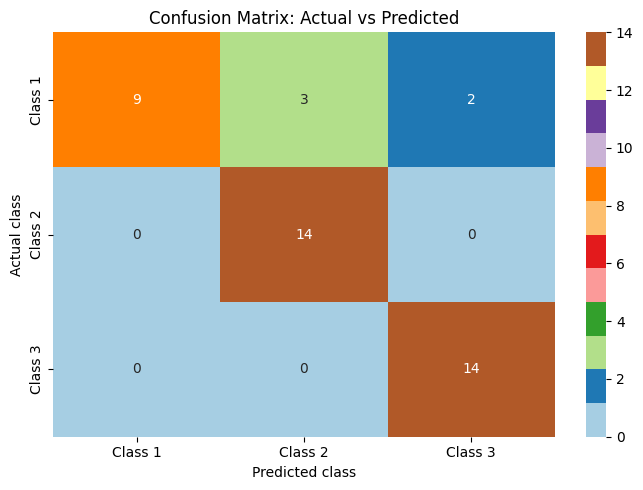

In [30]:
plt.figure(figsize=(7, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Paired", xticklabels=["Class 1", "Class 2", "Class 3"], yticklabels=["Class 1", "Class 2", "Class 3"])
plt.title("Confusion Matrix: Actual vs Predicted")
plt.xlabel("Predicted class")
plt.ylabel("Actual class")
plt.tight_layout()
plt.show()